# GPU audio fingerprint retrieval

This notebook compares angular LSH and exhaustive cosine search on the same GPU-resident 256-dimensional audio fingerprints. It selects the LSH settings on standard development tracks, then evaluates identification accuracy, unknown-song rejection, latency and throughput on held-out tracks.

The saved outputs use FMA medium. To reproduce them, [build the medium fingerprints and set up the CUDA notebook environment](../README.md#rebuilding-the-medium-fingerprints-on-a-gpu), then run all cells. To benchmark Nikos's v0.2 fingerprints, use the [small preset and commands](../README.md#running-the-gpu-retrieval-comparison). Each preset writes separate PDF/PNG figures and a JSON record. The [published-small results](../reports/gpu-retrieval-small.json) use the same development rule.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter, perf_counter_ns
import json, math, os, platform, sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/afp/gpu_retrieval.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository or a child directory.")
sys.path.insert(0, str(ROOT / "src"))

TAG = os.environ.get("AFP_DATASET_TAG", "medium").strip().lower()
if TAG not in {"small", "medium"}:
    raise ValueError("AFP_DATASET_TAG must be small or medium.")
DEFAULT_DATA_DIRS = {"small": ROOT / "data/processed/fingerprints", "medium": ROOT / "data/medium/data/processed/fingerprints"}
data_setting = os.environ.get("AFP_FINGERPRINT_DIR")
DATA_DIR = Path(data_setting) if data_setting else DEFAULT_DATA_DIRS[TAG]
if not DATA_DIR.is_absolute():
    DATA_DIR = ROOT / DATA_DIR
OUT = ROOT / "reports"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
JSON_PATH = OUT / f"gpu-retrieval-{TAG}.json"
PNG_PATH = FIG / f"gpu-retrieval-{TAG}.png"
PDF_PATH = FIG / f"gpu-retrieval-{TAG}.pdf"
cache_setting = os.environ.get("CUPY_CACHE_DIR")
cache_path = Path(cache_setting) if cache_setting else ROOT / "data/medium/cupy-cache"
if not cache_path.is_absolute():
    cache_path = ROOT / cache_path
os.environ["CUPY_CACHE_DIR"] = str(cache_path)

import cupy as cp
from afp.gpu_retrieval import GPUAngularLSH, gpu_exact

THRESHOLD = 0.70
INDEX_SEED = 2807
DEV_SEED = 2211
UNKNOWN_SEED = 0
DEV_TOLERANCE = 0.005
DEV_TIMING_N = 128
FINAL_TIMING_N = 256
EXACT_CHUNK = 128
BATCH_CHUNK = 128
BATCH_REPEATS = 4
LAYOUTS = ((10, 32), (12, 24), (14, 32), (10, 64))
PROBES = (0, 1, 3)
print(f"Dataset={TAG} · data={DATA_DIR}")
print(f"Python {platform.python_version()} · NumPy {np.__version__} · CuPy {cp.__version__}")

Dataset=medium · data=E:\DevPro\CompToolsProject\02807_computational_tools_ds\data\medium\data\processed\fingerprints
Python 3.12.11 · NumPy 2.5.5 · CuPy 14.2.0


E:\DevPro\CompToolsProject\02807_computational_tools_ds\.venv\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


## Data, validation, and split

Use the stable seed-2211 25% sample of distinct standard-query track IDs for tuning. Exclude those tracks from both held-out query sets. TikTok-like queries are not used for selection. The same split rule is applied to medium. The sampled vector checks below validate shapes, finite values, and unit norms; all nearest-neighbor retrieval is performed by GPU functions.

In [2]:
FILES = ("references.npz", "queries.npz", "queries_tiktok.npz")
SMALL_SHA256 = {"references.npz": "fb749ede9dd8cf363aac209d5d83ce74ca6e00a73a23ad8477d9d7ecb310fbba", "queries.npz": "dd6d0ef03e26158b037cd1a9842bfb2a9e88181d0ee1332fd896ce04833c802a", "queries_tiktok.npz": "a8095ab474849d9203bad548e76adab0773b4fc8f92791599c1e046f9138a404"}
def sha256_file(file_path):
    import hashlib
    with file_path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
missing = [name for name in FILES if not (DATA_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(
        "Missing local fingerprints: " + ", ".join(str(DATA_DIR / name) for name in missing)
        + ". Generate or place all three archives first; this notebook does not download them."
    )
input_digests = {name: sha256_file(DATA_DIR / name) for name in FILES}
if TAG == "small":
    bad = [name for name in FILES if input_digests[name] != SMALL_SHA256[name]]
    if bad:
        raise ValueError("Small inputs do not match v0.2 release SHA-256: " + ", ".join(bad))

def load_npz(name):
    with np.load(DATA_DIR / name, allow_pickle=False) as z:
        return {key: z[key] for key in z.files}

ref_data = load_npz("references.npz")
std_data = load_npz("queries.npz")
tt_data = load_npz("queries_tiktok.npz")
R = np.ascontiguousarray(ref_data["vectors"], dtype=np.float32)
rt = np.ascontiguousarray(ref_data["track_id"], dtype=np.int32)

def unpack(data, label):
    q = np.ascontiguousarray(data["vectors"], dtype=np.float32)
    y = np.ascontiguousarray(data["track_id"], dtype=np.int32)
    d = np.asarray(data.get("augmentation", np.full(len(q), "unspecified"))).astype(str)
    if q.ndim != 2 or q.shape[1] != 256 or y.shape != (len(q),) or d.shape != y.shape:
        raise ValueError(f"Bad {label} archive schema; expected vectors [N,256], track_id and augmentation.")
    return q, y, d

Qstd, ystd, dstd = unpack(std_data, "standard")
Qtt, ytt, dtt = unpack(tt_data, "TikTok-like")
if R.ndim != 2 or R.shape[1] != 256 or rt.shape != (len(R),) or not len(R):
    raise ValueError("Expected nonempty references [N,256] and one reference track ID per row.")
if not len(Qstd) or not len(Qtt):
    raise ValueError("Both query archives must be nonempty.")

check_rng = np.random.default_rng(2807)
rs = R[check_rng.choice(len(R), min(4096, len(R)), replace=False)]
qs = np.concatenate((Qstd[:512], Qtt[:512]))
if not np.isfinite(rs).all() or not np.isfinite(qs).all():
    raise ValueError("Sampled fingerprint values must be finite.")
if not np.allclose(np.linalg.norm(rs, axis=1), 1, atol=2e-4):
    raise ValueError("Reference fingerprints are not unit norm.")
if not np.allclose(np.linalg.norm(qs, axis=1), 1, atol=2e-4):
    raise ValueError("Query fingerprints are not unit norm.")

dev_track_ids = np.random.default_rng(DEV_SEED).choice(
    np.unique(ystd), size=len(np.unique(ystd)) // 4, replace=False
)
dev_mask = np.isin(ystd, dev_track_ids)
Qdev, ydev = Qstd[dev_mask], ystd[dev_mask]
heldout = []
for name, q, y, d in (("Standard", Qstd, ystd, dstd), ("TikTok-like", Qtt, ytt, dtt)):
    keep = ~np.isin(y, dev_track_ids)
    heldout.append((q[keep], pd.DataFrame({
        "query_set": name, "distortion": d[keep], "track_id": y[keep]
    })))
Qtest = np.ascontiguousarray(np.concatenate([part[0] for part in heldout]), dtype=np.float32)
meta = pd.concat([part[1] for part in heldout], ignore_index=True)
ytest = meta.track_id.to_numpy(dtype=np.int32)
if np.intersect1d(dev_track_ids, ytest).size:
    raise AssertionError("Development track IDs leaked into held-out queries.")
input_files = {
    name: {"path": Path(os.path.relpath(DATA_DIR / name, ROOT)).as_posix(),
        "size_bytes": (DATA_DIR / name).stat().st_size, "sha256": input_digests[name]}
    for name in FILES
}
dataset = {
    "reference_windows": int(len(R)), "reference_tracks": int(np.unique(rt).size),
    "dimension": 256, "dev_tracks": int(len(dev_track_ids)),
    "dev_queries": int(len(Qdev)), "heldout_queries": int(len(Qtest)),
    "heldout_by_set": {str(k): int(v) for k, v in meta.groupby("query_set").size().items()},
    "files": input_files,
}
display(pd.DataFrame([
    {"partition": "Development · standard", "queries": len(Qdev)},
    *[{"partition": name, "queries": count} for name, count in dataset["heldout_by_set"].items()],
]))
print(f"{len(R):,} reference windows · {np.unique(rt).size:,} searchable tracks")

,partition,queries
0,Development · standard,2542
1,Standard,7458
2,TikTok-like,8992


110,320 reference windows · 24,970 searchable tracks


## GPU setup

Upload each input once. Timings exclude file access, host-to-device upload, and index construction. Single-query measurements include the API call and explicit CUDA synchronization. The exact baseline is chunked to bound its temporary score matrix; both methods use the same resident query batch for throughput.

In [3]:
device = cp.cuda.Device()
props = cp.cuda.runtime.getDeviceProperties(device.id)
raw_name = props["name"]
gpu_name = raw_name.decode(errors="replace") if isinstance(raw_name, bytes) else str(raw_name)
def sync_gpu():
    cp.cuda.runtime.deviceSynchronize()

upload_start = perf_counter()
Rg = cp.ascontiguousarray(cp.asarray(R, dtype=cp.float32))
rtg = cp.ascontiguousarray(cp.asarray(rt, dtype=cp.int32))
Qdevg = cp.ascontiguousarray(cp.asarray(Qdev, dtype=cp.float32))
Qtestg = cp.ascontiguousarray(cp.asarray(Qtest, dtype=cp.float32))
sync_gpu()
upload_s = perf_counter() - upload_start
gpu = {
    "device": gpu_name, "device_id": int(device.id),
    "compute_capability": str(device.compute_capability),
    "cupy": cp.__version__, "cuda_runtime": int(cp.cuda.runtime.runtimeGetVersion()),
    "cuda_driver": int(cp.cuda.runtime.driverGetVersion()), "upload_seconds": float(upload_s),
}
print(gpu)

{'device': 'NVIDIA GeForce RTX 4090', 'device_id': 0, 'compute_capability': '89', 'cupy': '14.2.0', 'cuda_runtime': 12090, 'cuda_driver': 13050, 'upload_seconds': 0.10270560000208206}


## Development sweep and frozen selection rule

Evaluate layouts 10×32, 12×24, 14×32, and 10×64 with 0, 1, or 3 probes per table. Select the fastest median single-query configuration within 0.5 percentage points of exact development accuracy. If none qualifies, select highest development accuracy, then fastest latency. This same rule is predeclared for medium. The held-out query outcomes do not choose the index.

The default evaluation reuses the settings selected in each catalogue's first development run. Microsecond timing variation across reruns can change which qualifying configuration ranks first. The sweep also reports the live choice. Set `AFP_RETUNE=1` to use live development timings on your own GPU.

In [4]:
def exact_batch(qg, rg=Rg, tg=rtg, chunk=EXACT_CHUNK):
    tracks, scores = [], []
    for start in range(0, len(qg), chunk):
        a, b = gpu_exact(rg, tg, qg[start:start + chunk])
        tracks.append(a)
        scores.append(b)
    return cp.concatenate(tracks), cp.concatenate(scores)

def paired_times(exact_fn, lsh_fn, qg, order):
    for i in order[:min(12, len(order))]:
        exact_fn(qg[i:i + 1])
        lsh_fn(qg[i:i + 1])
    sync_gpu()
    result = {"exact": [], "lsh": []}
    for j, i in enumerate(order):
        calls = [("exact", exact_fn), ("lsh", lsh_fn)]
        if j % 2:
            calls.reverse()
        for name, fn in calls:
            start = perf_counter_ns()
            fn(qg[i:i + 1])
            sync_gpu()
            result[name].append((perf_counter_ns() - start) / 1e6)
    return {key: np.asarray(values) for key, values in result.items()}

def summary_ms(values):
    return {"median_ms": float(np.median(values)), "p95_ms": float(np.percentile(values, 95)),
            "n": int(len(values))}

# Compile/warm the CUDA functions on a sacrificial tiny index; exclude this from full build costs.
warm_start = perf_counter()
warm_n = min(1024, len(Rg))
warm = GPUAngularLSH(Rg[:warm_n], rtg[:warm_n], bits=10, tables=1, seed=INDEX_SEED)
warm.search(Qdevg[:1], probes=0)
gpu_exact(Rg, rtg, Qdevg[:1])
sync_gpu()
kernel_warmup_s = perf_counter() - warm_start
del warm

dev_exact_g, dev_score_g = exact_batch(Qdevg)
sync_gpu()
dev_exact = cp.asnumpy(dev_exact_g)
dev_scores = cp.asnumpy(dev_score_g)
exact_dev_acc = float(np.mean(dev_exact == ydev))
dev_order = np.random.default_rng(20261122).choice(
    len(Qdev), size=min(DEV_TIMING_N, len(Qdev)), replace=False
)
indices, rows = {}, []
for bits, tables in LAYOUTS:
    start = perf_counter()
    index = GPUAngularLSH(Rg, rtg, bits=bits, tables=tables, seed=INDEX_SEED)
    sync_gpu()
    build_s = perf_counter() - start
    indices[(bits, tables)] = index
    for probes in PROBES:
        pt, ps, visits = index.search(Qdevg, probes=probes)
        sync_gpu()
        pred, score, count = cp.asnumpy(pt), cp.asnumpy(ps), cp.asnumpy(visits)
        if np.any(score > dev_scores + 2e-5):
            raise AssertionError("LSH score exceeded exact cosine score beyond tolerance.")
        if np.any((pred != -1) & ~np.isin(pred, rt)):
            raise AssertionError("LSH returned a track outside the reference catalogue.")
        times = paired_times(
            lambda q: gpu_exact(Rg, rtg, q),
            lambda q, ix=index, p=probes: ix.search(q, probes=p),
            Qdevg, dev_order
        )
        rows.append({
            "bits": bits, "tables": tables, "probes": probes,
            "dev_accuracy": float(np.mean(pred == ydev)),
            "dev_exact_agreement": float(np.mean(pred == dev_exact)),
            "mean_window_visits": float(np.mean(count)),
            "catalogue_visit_fraction": float(np.mean(count) / len(R)),
            "build_seconds": float(build_s),
            "dev_exact_median_ms": float(np.median(times["exact"])),
            "dev_lsh_median_ms": float(np.median(times["lsh"])),
            "dev_lsh_p95_ms": float(np.percentile(times["lsh"], 95)),
            "dev_timing_queries": int(len(dev_order)),
        })
        del pt, ps, visits, pred, score, count

sweep = pd.DataFrame(rows)
eligible = sweep[sweep.dev_accuracy >= exact_dev_acc - DEV_TOLERANCE]
if len(eligible):
    selected = eligible.sort_values(
        ["dev_lsh_median_ms", "mean_window_visits", "bits", "tables", "probes"]
    ).iloc[0]
    selection_rule = "fastest within 0.5 pp of exact development accuracy"
else:
    selected = sweep.sort_values(
        ["dev_accuracy", "dev_lsh_median_ms"], ascending=[False, True]
    ).iloc[0]
    selection_rule = "highest development accuracy; latency breaks ties"
live_choice = [int(selected.bits), int(selected.tables), int(selected.probes)]
retune = os.environ.get("AFP_RETUNE", "0") == "1"
if not retune:
    recorded = {"small": (10, 64, 0), "medium": (14, 32, 3)}[TAG]
    selected = sweep[(sweep.bits == recorded[0]) & (sweep.tables == recorded[1]) &
                     (sweep.probes == recorded[2])].iloc[0]
    selection_rule = "frozen first development run: fastest within 0.5 pp of exact"
bits, tables, probes = int(selected.bits), int(selected.tables), int(selected.probes)
ann = indices[(bits, tables)]
choice = {
    "bits": bits, "tables": tables, "probes": probes, "selection_rule": selection_rule,
    "current_sweep_choice": live_choice, "retuned": retune,
    "dev_accuracy": float(selected.dev_accuracy), "exact_dev_accuracy": exact_dev_acc,
    "mean_window_visits": float(selected.mean_window_visits),
    "index_build_seconds": float(selected.build_seconds),
}
for key in list(indices):
    if key != (bits, tables):
        del indices[key]
del indices
display(sweep.sort_values(["bits", "tables", "probes"]).round(5))
display(Markdown(f"**Selected:** {bits} bits × {tables} tables, {probes} probes; "
                 f"development accuracy {choice['dev_accuracy']:.2%}, exact {exact_dev_acc:.2%}."))

,bits,tables,probes,dev_accuracy,dev_exact_agreement,mean_window_visits,catalogue_visit_fraction,build_seconds,dev_exact_median_ms,dev_lsh_median_ms,dev_lsh_p95_ms,dev_timing_queries
0,10,32,0,0.96774,0.98702,4637.36428,0.04204,0.03427,0.19950,0.05865,0.07065,128
1,10,32,1,0.97561,0.99607,9178.77773,0.08320,0.03427,0.19895,0.06850,0.08569,128
2,10,32,3,0.97718,0.99882,17972.84225,0.16292,0.03427,0.19075,0.07960,0.09962,128
9,10,64,0,0.97640,0.99685,9203.14201,0.08342,0.03039,0.19120,0.05890,0.14699,128
10,10,64,1,0.97679,0.99882,18214.93155,0.16511,0.03039,0.18650,0.06760,0.08355,128
11,10,64,3,0.97758,1.00000,35692.92250,0.32354,0.03039,0.17950,0.08200,0.19188,128
3,12,24,0,0.93391,0.94925,986.17467,0.00894,0.01169,0.19250,0.05030,0.06258,128
4,12,24,1,0.95948,0.97758,1949.23092,0.01767,0.01169,0.19200,0.05405,0.06224,128
5,12,24,3,0.97286,0.99292,3816.47797,0.03459,0.01169,0.19140,0.05850,0.07086,128
6,14,32,0,0.92250,0.93824,385.49843,0.00349,0.01431,0.19250,0.05110,0.06375,128


**Selected:** 14 bits × 32 tables, 3 probes; development accuracy 97.29%, exact 97.76%.

## Held-out retrieval accuracy and distortions

After selection, freeze the index and evaluate all held-out standard and TikTok-like queries. Candidate visits include duplicate windows visited by different hash tables. The score check verifies LSH never exceeds the exhaustive maximum beyond small FP32 reduction tolerance.

In [5]:
ltg, lsg, vsg = ann.search(Qtestg, probes=probes)
etg, esg = exact_batch(Qtestg)
sync_gpu()
lp, ls, visits = cp.asnumpy(ltg), cp.asnumpy(lsg), cp.asnumpy(vsg)
ep, es = cp.asnumpy(etg), cp.asnumpy(esg)
if lp.shape != ytest.shape or ep.shape != ytest.shape:
    raise AssertionError("Prediction arrays do not align with held-out query rows.")
if np.any((lp != -1) & ~np.isin(lp, rt)) or np.any(ls > es + 2e-5):
    raise AssertionError("LSH output failed catalogue-ID or exact-score checks.")

def closed_row(name, ids):
    truth = ytest[ids]
    return {
        "query_set": name, "queries": int(len(ids)),
        "exact_track_accuracy": float(np.mean(ep[ids] == truth)),
        "lsh_track_accuracy": float(np.mean(lp[ids] == truth)),
        "exact_agreement": float(np.mean(ep[ids] == lp[ids])),
        "lsh_empty_results": int(np.sum(lp[ids] == -1)),
        "mean_window_visits": float(np.mean(visits[ids])),
        "catalogue_visit_fraction": float(np.mean(visits[ids]) / len(R)),
    }

closed = pd.DataFrame([
    closed_row(name, group.index.to_numpy(dtype=np.int64))
    for name, group in meta.groupby("query_set", sort=False)
])
distortion_rows = []
for (name, distortion), group in meta.groupby(["query_set", "distortion"], sort=True):
    ids = group.index.to_numpy(dtype=np.int64)
    distortion_rows.append({
        "query_set": name, "distortion": distortion, "queries": int(len(ids)),
        "exact_track_accuracy": float(np.mean(ep[ids] == ytest[ids])),
        "lsh_track_accuracy": float(np.mean(lp[ids] == ytest[ids])),
        "exact_agreement": float(np.mean(ep[ids] == lp[ids])),
        "mean_window_visits": float(np.mean(visits[ids])),
    })
distortion = pd.DataFrame(distortion_rows)
display(closed.round(5))
display(distortion.round(4))

,query_set,queries,exact_track_accuracy,lsh_track_accuracy,exact_agreement,lsh_empty_results,mean_window_visits,catalogue_visit_fraction
0,Standard,7458,0.98083,0.97251,0.98847,0,1488.06074,0.01349
1,TikTok-like,8992,0.93539,0.89524,0.92949,0,1489.81172,0.01350


,query_set,distortion,queries,exact_track_accuracy,lsh_track_accuracy,exact_agreement,mean_window_visits
0,Standard,band_pass,749,0.9826,0.9760,0.9893,1472.2016
1,Standard,echo,739,0.9851,0.9811,0.9946,1489.9486
2,Standard,high_pass,812,0.9889,0.9865,0.9975,1472.9877
3,Standard,low_pass,728,0.9890,0.9863,0.9959,1481.7527
4,Standard,noise,800,0.9662,0.9538,0.9762,1485.7725
5,Standard,pitch_shift,746,0.9853,0.9772,0.9893,1494.7534
6,Standard,reverb,748,0.9840,0.9813,0.9973,1517.0107
7,Standard,reverb+noise,764,0.9660,0.9542,0.9791,1482.4058
8,Standard,time_stretch,686,0.9840,0.9810,0.9971,1490.8513
9,Standard,time_stretch+pitch_shift,686,0.9781,0.9475,0.9679,1495.2099


## Synchronized GPU speed

Single-query latency uses up to 256 held-out queries, a warm-up, fixed random order, alternating method order, and explicit synchronization after each call. Throughput uses the full held-out query matrix, identical 128-query chunks for exact and LSH, four runs with alternating method order, and synchronization after each full pass. Inputs remain resident on the GPU.

In [6]:
def lsh_batch(qg, ix=ann, probe_count=probes, chunk=BATCH_CHUNK):
    tracks, scores, counts = [], [], []
    for start in range(0, len(qg), chunk):
        a, b, c = ix.search(qg[start:start + chunk], probes=probe_count)
        tracks.append(a)
        scores.append(b)
        counts.append(c)
    return cp.concatenate(tracks), cp.concatenate(scores), cp.concatenate(counts)

test_order = np.random.default_rng(4422).choice(
    len(Qtest), size=min(FINAL_TIMING_N, len(Qtest)), replace=False
)
single = paired_times(
    lambda q: gpu_exact(Rg, rtg, q),
    lambda q: ann.search(q, probes=probes),
    Qtestg, test_order
)
batch_fns = {"exact": exact_batch, "selected_lsh": lsh_batch}
warm_batch = Qtestg[:min(BATCH_CHUNK, len(Qtest))]
exact_batch(warm_batch)
lsh_batch(warm_batch)
sync_gpu()
batch_seconds = {"exact": [], "selected_lsh": []}
for repeat in range(BATCH_REPEATS):
    order = ("exact", "selected_lsh") if repeat % 2 == 0 else ("selected_lsh", "exact")
    for method in order:
        sync_gpu()
        start = perf_counter()
        batch_fns[method](Qtestg)
        sync_gpu()
        batch_seconds[method].append(perf_counter() - start)
batch = {}
for method, values in batch_seconds.items():
    median_s = float(np.median(values))
    batch[method] = {
        "median_seconds": median_s,
        "p95_seconds": float(np.percentile(values, 95)),
        "median_queries_per_second": float(len(Qtest) / median_s),
        "queries": int(len(Qtest)), "chunk_size": BATCH_CHUNK, "repeats": BATCH_REPEATS,
    }
speed = {
    "single_query": {
        "sample_queries": int(len(test_order)),
        "exact": summary_ms(single["exact"]),
        "selected_lsh": summary_ms(single["lsh"]),
        "method": "resident batch size 1; warm; sync per call; counterbalanced",
    },
    "resident_batch": batch,
    "kernel_compile_and_warmup_seconds": float(kernel_warmup_s),
    "host_to_device_upload_seconds": float(upload_s),
    "selected_index_build_seconds": choice["index_build_seconds"],
}
display(pd.DataFrame([
    {"method": "GPU exact", "median single ms": speed["single_query"]["exact"]["median_ms"],
     "p95 single ms": speed["single_query"]["exact"]["p95_ms"],
     "median batch q/s": batch["exact"]["median_queries_per_second"]},
    {"method": "GPU LSH", "median single ms": speed["single_query"]["selected_lsh"]["median_ms"],
     "p95 single ms": speed["single_query"]["selected_lsh"]["p95_ms"],
     "median batch q/s": batch["selected_lsh"]["median_queries_per_second"]},
]).round(3))

,method,median single ms,p95 single ms,median batch q/s
0,GPU exact,0.196,0.206,365938.571
1,GPU LSH,0.052,0.066,1097160.389


## Open-set evaluation at 0.70

Do not tune this threshold on the current results. Following the project evaluation, remove half of held-out query track IDs with a fixed seed. A query is known only when its true track remains in the reduced reference set; naturally absent query tracks are also unknown. Report correct known acceptance and unknown false acceptance separately, plus their balanced score. Distortion rows retain separate denominators.

In [7]:
removed = np.random.default_rng(UNKNOWN_SEED).choice(
    np.unique(ytest), size=len(np.unique(ytest)) // 2, replace=False
)
keep = ~np.isin(rt, removed)
Ropen = Rg[cp.asarray(keep)]
rtopen = rtg[cp.asarray(keep)]
rtopen_host = rt[keep]
known = np.isin(ytest, np.unique(rtopen_host))
if not known.any() or known.all():
    raise ValueError("Open-set split must contain known and unknown queries.")
open_start = perf_counter()
ann_open = GPUAngularLSH(Ropen, rtopen, bits=bits, tables=tables, seed=INDEX_SEED)
sync_gpu()
open_build_s = perf_counter() - open_start
opt, ost, ov = ann_open.search(Qtestg, probes=probes)
oet, oes = exact_batch(Qtestg, Ropen, rtopen)
sync_gpu()
op, oscore, ovis = cp.asnumpy(opt), cp.asnumpy(ost), cp.asnumpy(ov)
oep, oesc = cp.asnumpy(oet), cp.asnumpy(oes)

def open_metric(pred, score, truth, known_mask):
    unknown_mask = ~known_mask
    accepted = score >= THRESHOLD
    correct = (pred == truth) & accepted
    wrong = (pred != truth) & accepted
    nk, nu = int(known_mask.sum()), int(unknown_mask.sum())
    kcorrect = float(correct[known_mask].mean()) if nk else None
    ufa = float(accepted[unknown_mask].mean()) if nu else None
    return {
        "known_queries": nk, "unknown_queries": nu,
        "known_acceptance_rate": float(accepted[known_mask].mean()) if nk else None,
        "known_correct_acceptance": kcorrect,
        "known_wrong_acceptance": float(wrong[known_mask].mean()) if nk else None,
        "unknown_false_acceptance": ufa,
        "unknown_rejection": 1.0 - ufa if ufa is not None else None,
        "balanced_open_score": (kcorrect + 1.0 - ufa) / 2.0 if kcorrect is not None and ufa is not None else None,
    }

open_results = pd.DataFrame([
    {"method": "GPU exact", **open_metric(oep, oesc, ytest, known)},
    {"method": "GPU LSH", **open_metric(op, oscore, ytest, known)},
])
open_by_distortion = []
for (name, aug), group in meta.groupby(["query_set", "distortion"], sort=True):
    ids = group.index.to_numpy(dtype=np.int64)
    for method, pred, score in (("GPU exact", oep, oesc), ("GPU LSH", op, oscore)):
        open_by_distortion.append({
            "query_set": name, "distortion": aug, "method": method,
            **open_metric(pred[ids], score[ids], ytest[ids], known[ids]),
        })
open_distortion = pd.DataFrame(open_by_distortion)
open_info = {
    "threshold": THRESHOLD, "removed_track_ids_count": int(len(removed)),
    "naturally_absent_query_track_ids": int(len(np.setdiff1d(np.unique(ytest), np.unique(rt)))),
    "known_queries": int(known.sum()), "unknown_queries": int((~known).sum()),
    "reference_windows_after_removal": int(keep.sum()),
    "open_index_build_seconds": float(open_build_s),
}
display(open_results.round(5))
display(open_distortion.round(4))

,method,known_queries,unknown_queries,known_acceptance_rate,known_correct_acceptance,known_wrong_acceptance,unknown_false_acceptance,unknown_rejection,balanced_open_score
0,GPU exact,8167,8283,0.85356,0.84609,0.00747,0.06350,0.93650,0.89129
1,GPU LSH,8167,8283,0.84315,0.83580,0.00735,0.05988,0.94012,0.88796


,query_set,distortion,method,known_queries,unknown_queries,known_acceptance_rate,known_correct_acceptance,known_wrong_acceptance,unknown_false_acceptance,unknown_rejection,balanced_open_score
0,Standard,band_pass,GPU exact,376,373,0.9894,0.9840,0.0053,0.0804,0.9196,0.9518
1,Standard,band_pass,GPU LSH,376,373,0.9867,0.9814,0.0053,0.0777,0.9223,0.9518
2,Standard,echo,GPU exact,349,390,0.9885,0.9742,0.0143,0.0667,0.9333,0.9538
3,Standard,echo,GPU LSH,349,390,0.9828,0.9685,0.0143,0.0667,0.9333,0.9509
4,Standard,high_pass,GPU exact,408,404,0.9877,0.9804,0.0074,0.0569,0.9431,0.9617
5,Standard,high_pass,GPU LSH,408,404,0.9877,0.9804,0.0074,0.0569,0.9431,0.9617
6,Standard,low_pass,GPU exact,370,358,0.9946,0.9892,0.0054,0.0950,0.9050,0.9471
7,Standard,low_pass,GPU LSH,370,358,0.9946,0.9892,0.0054,0.0838,0.9162,0.9527
8,Standard,noise,GPU exact,392,408,0.9260,0.9158,0.0102,0.0637,0.9363,0.9260
9,Standard,noise,GPU LSH,392,408,0.9235,0.9133,0.0102,0.0539,0.9461,0.9297


## Report figure and results record

The development panel shows only selection evidence. Other panels show held-out closed-set accuracy, open-set rates, and GPU timing for exact and the selected LSH index. The JSON retains the sweep and per-distortion values for auditing.

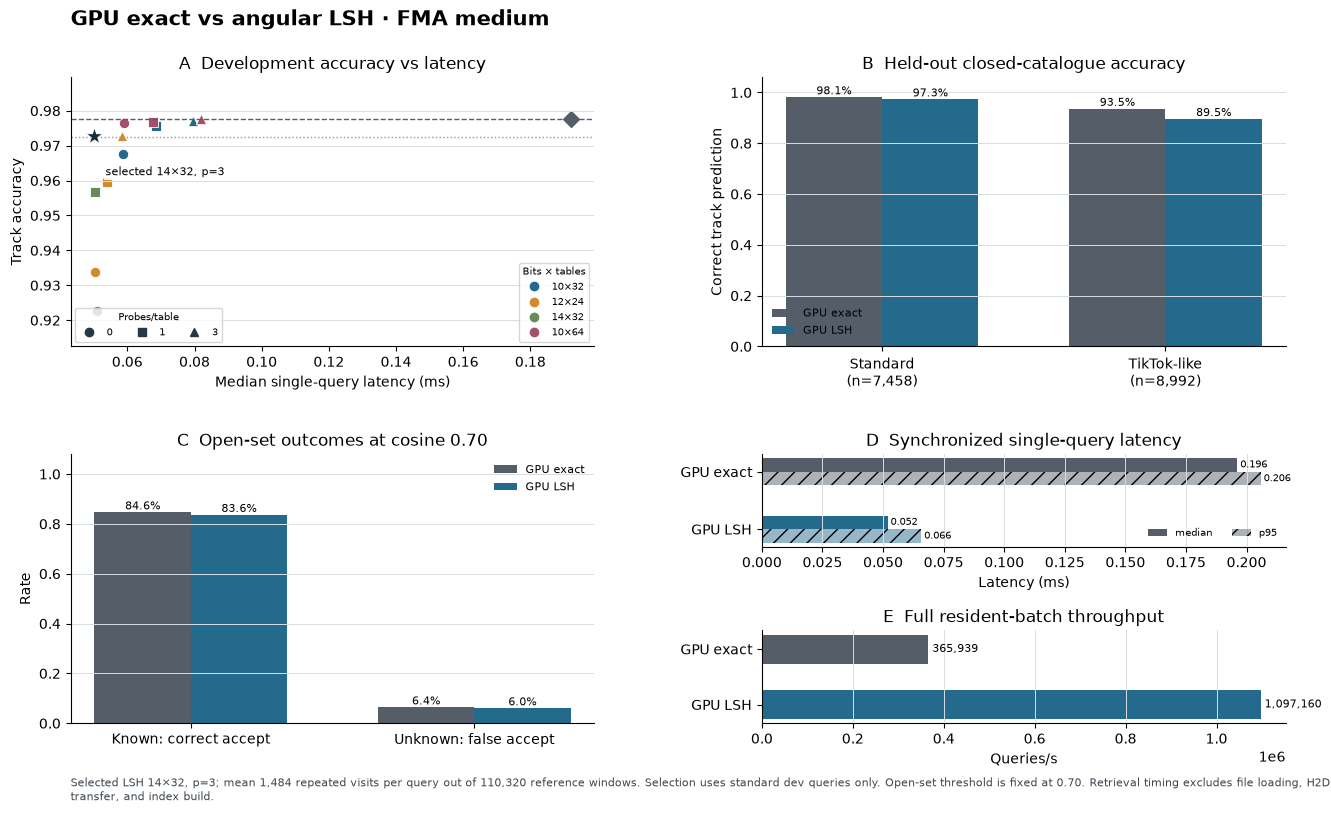

Saved reports\gpu-retrieval-medium.json
Saved reports\figures\gpu-retrieval-medium.pdf and reports\figures\gpu-retrieval-medium.png


In [8]:
colors = {(10, 32): "#246A8D", (12, 24): "#D18B2C", (14, 32): "#688B57", (10, 64): "#A84F68"}
markers = {0: "o", 1: "s", 3: "^"}
exact_color, lsh_color = "#555E68", "#246A8D"
fig = plt.figure(figsize=(13.5, 8.5))
gs = fig.add_gridspec(2, 2, left=.08, right=.98, top=.9, bottom=.14, hspace=.4, wspace=.32)
a = fig.add_subplot(gs[0, 0])
b = fig.add_subplot(gs[0, 1])
c = fig.add_subplot(gs[1, 0])
spd = gs[1, 1].subgridspec(2, 1, hspace=.9)
d = fig.add_subplot(spd[0, 0])
e = fig.add_subplot(spd[1, 0])
for (nbits, ntables), group in sweep.groupby(["bits", "tables"], sort=False):
    for _, row in group.iterrows():
        a.scatter(row.dev_lsh_median_ms, row.dev_accuracy, s=55,
                  color=colors[(int(nbits), int(ntables))], marker=markers[int(row.probes)],
                  edgecolor="white", linewidth=.6)
exact_ms = float(sweep.dev_exact_median_ms.median())
a.scatter(exact_ms, exact_dev_acc, marker="D", s=65, color=exact_color, label="Exact")
a.axhline(exact_dev_acc, color=exact_color, ls="--", lw=1)
a.axhline(exact_dev_acc - DEV_TOLERANCE, color="#9299A1", ls=":", lw=1)
a.scatter(float(selected.dev_lsh_median_ms), float(selected.dev_accuracy), marker="*", s=170,
          color="#172B3A", edgecolor="white", linewidth=.7, zorder=5)
a.annotate(f"selected {bits}×{tables}, p={probes}",
           (float(selected.dev_lsh_median_ms), float(selected.dev_accuracy)),
           xytext=(8, -22), textcoords="offset points", va="top", fontsize=8,
           bbox={"boxstyle": "round,pad=.2", "fc": "white", "ec": "none", "alpha": .92})
handles = [Line2D([0], [0], marker="o", linestyle="", color=color, label=f"{x}×{y}")
           for (x, y), color in colors.items()]
leg = a.legend(handles=handles, title="Bits × tables", loc="lower right", fontsize=7, title_fontsize=7)
a.add_artist(leg)
a.legend(handles=[Line2D([0], [0], marker=markers[p], linestyle="", color="#263746", label=str(p))
                  for p in PROBES], title="Probes/table", loc="lower left", ncol=3,
         fontsize=7, title_fontsize=7)
acc_low = max(0.0, min(float(sweep.dev_accuracy.min()), exact_dev_acc) - 0.01)
acc_high = min(1.01, max(float(sweep.dev_accuracy.max()), exact_dev_acc) + 0.012)
a.set(title="A  Development accuracy vs latency", xlabel="Median single-query latency (ms)",
      ylabel="Track accuracy", ylim=(acc_low, acc_high))
a.grid(axis="y", color="#D9DDE1", lw=.7)
a.spines[["top", "right"]].set_visible(False)

sets = ["Standard", "TikTok-like"]
x = np.arange(2)
w = .34
for shift, method, color, col in ((-w/2, "GPU exact", exact_color, "exact_track_accuracy"),
                                  (w/2, "GPU LSH", lsh_color, "lsh_track_accuracy")):
    vals = [float(closed.loc[closed.query_set == s, col].iloc[0]) for s in sets]
    bars = b.bar(x + shift, vals, w, color=color, label=method)
    for bar, val in zip(bars, vals, strict=True):
        b.text(bar.get_x() + bar.get_width()/2, val + .012, f"{val:.1%}", ha="center", fontsize=8)
counts = [int(closed.loc[closed.query_set == s, "queries"].iloc[0]) for s in sets]
b.set_xticks(x, [f"{s}\n(n={n:,})" for s, n in zip(sets, counts, strict=True)])
b.set(title="B  Held-out closed-catalogue accuracy", ylabel="Correct track prediction", ylim=(0, 1.06))
b.legend(loc="lower left", frameon=False, fontsize=8)
b.grid(axis="y", color="#D9DDE1", lw=.7)
b.spines[["top", "right"]].set_visible(False)

open_labels = [("Known: correct accept", "known_correct_acceptance"),
               ("Unknown: false accept", "unknown_false_acceptance")]
for shift, method, color in ((-w/2, "GPU exact", exact_color), (w/2, "GPU LSH", lsh_color)):
    vals = []
    for _, col in open_labels:
        value = open_results.loc[open_results.method == method, col].iloc[0]
        vals.append(float(value) if value is not None and not pd.isna(value) else 0)
    bars = c.bar(x + shift, vals, w, color=color, label=method)
    for bar, val in zip(bars, vals, strict=True):
        c.text(bar.get_x() + bar.get_width()/2, val + .012, f"{val:.1%}", ha="center", fontsize=8)
c.set_xticks(x, [label for label, _ in open_labels])
c.set(title="C  Open-set outcomes at cosine 0.70", ylabel="Rate", ylim=(0, 1.08))
c.legend(frameon=False, fontsize=8)
c.grid(axis="y", color="#D9DDE1", lw=.7)
c.spines[["top", "right"]].set_visible(False)

names = ["GPU exact", "GPU LSH"]
med = [speed["single_query"]["exact"]["median_ms"], speed["single_query"]["selected_lsh"]["median_ms"]]
p95 = [speed["single_query"]["exact"]["p95_ms"], speed["single_query"]["selected_lsh"]["p95_ms"]]
y = np.arange(2)
d.barh(y - .12, med, height=.23, color=[exact_color, lsh_color], label="median")
d.barh(y + .12, p95, height=.23, color=[exact_color, lsh_color], alpha=.48, hatch="//", label="p95")
for i, val in enumerate(med):
    d.text(val, i - .12, f" {val:.3f}", va="center", fontsize=7)
for i, val in enumerate(p95):
    d.text(val, i + .12, f" {val:.3f}", va="center", fontsize=7)
d.set_yticks(y, names)
d.invert_yaxis()
d.set(title="D  Synchronized single-query latency", xlabel="Latency (ms)")
d.legend(frameon=False, fontsize=7, ncol=2, loc="lower right")
d.grid(axis="x", color="#D9DDE1", lw=.7)
d.spines[["top", "right"]].set_visible(False)
throughput = [batch["exact"]["median_queries_per_second"],
              batch["selected_lsh"]["median_queries_per_second"]]
e.barh(y, throughput, color=[exact_color, lsh_color], height=.52)
for i, val in enumerate(throughput):
    e.text(val, i, f" {val:,.0f}", va="center", fontsize=8)
e.set_yticks(y, names)
e.invert_yaxis()
e.set(title="E  Full resident-batch throughput", xlabel="Queries/s")
e.grid(axis="x", color="#D9DDE1", lw=.7)
e.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"GPU exact vs angular LSH · FMA {TAG}", x=.08, ha="left", fontsize=15, weight="bold")
fig.text(.08, .045,
         f"Selected LSH {bits}×{tables}, p={probes}; mean {choice['mean_window_visits']:,.0f} repeated visits "
         f"per query out of {len(R):,} reference windows. Selection uses standard dev queries only. "
         "Open-set threshold is fixed at 0.70. Retrieval timing excludes file loading, H2D transfer, and index build.",
         ha="left", va="bottom", fontsize=8, color="#3E4851", wrap=True)
fig.savefig(PNG_PATH, dpi=220, bbox_inches="tight", facecolor="white")
fig.savefig(PDF_PATH, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

def clean(value):
    if isinstance(value, dict):
        return {str(k): clean(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [clean(v) for v in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value

report = {
    "schema_version": 1, "dataset_tag": TAG,
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "source": {"fingerprint_directory": Path(os.path.relpath(DATA_DIR, ROOT)).as_posix(),
               "small_release": "v0.2-fingerprints" if TAG == "small" else None,
               "files": input_files},
    "dataset": dataset, "gpu": gpu, "selection": choice,
    "method": {
        "exact": "GPU exhaustive FP32 cosine, 128-query chunks",
        "lsh": "GPU random hyperplanes with nearest-boundary probes and cosine scoring",
        "seed": INDEX_SEED, "layouts": [{"bits": x, "tables": y} for x, y in LAYOUTS],
        "probes": list(PROBES), "fixed_open_set_threshold": THRESHOLD,
        "visits_include_repeated_windows": True,
    },
    "split": {"dev_seed": DEV_SEED, "dev_track_share": .25,
              "dev_query_set": "Standard only", "dev_tracks_excluded_from_heldout": True,
              "unknown_seed": UNKNOWN_SEED},
    "development_sweep": clean(sweep.to_dict(orient="records")),
    "heldout_closed": clean(closed.to_dict(orient="records")),
    "heldout_by_distortion": clean(distortion.to_dict(orient="records")),
    "open_set": {**open_info, "results": clean(open_results.to_dict(orient="records")),
                 "by_distortion": clean(open_distortion.to_dict(orient="records"))},
    "timing": {**speed, "open_index_build_seconds": float(open_build_s)},
    "checks": {"sampled_inputs_finite_unit_norm": True,
               "dev_tracks_disjoint_from_heldout": True,
               "lsh_ids_in_catalogue_or_minus_one": True,
               "lsh_scores_le_exact_with_2e-5_tolerance": True},
    "figures": {"png": str(PNG_PATH.relative_to(ROOT)), "pdf": str(PDF_PATH.relative_to(ROOT))},
    "limitations": [
        "Precomputed fingerprints are used; audio decode, fingerprint generation, and disk reads are excluded.",
        "GPU measurements are device- and runtime-specific; batch queries remain on device.",
        "Open-set false acceptance reflects a seeded simulated missing-song catalogue at fixed threshold 0.70.",
        "Synthetic distortions do not cover all real recordings or platform processing.",
    ],
}
JSON_PATH.write_text(json.dumps(clean(report), indent=2, allow_nan=False), encoding="utf-8")
print(f"Saved {JSON_PATH.relative_to(ROOT)}")
print(f"Saved {PDF_PATH.relative_to(ROOT)} and {PNG_PATH.relative_to(ROOT)}")

## Accuracy-first sensitivity analysis

The main benchmark chooses the fastest configuration within 0.5 percentage points of exact development accuracy. After observing the primary medium result, we added this exploratory comparison to quantify the cost of prioritising accuracy. It chooses the highest standard development accuracy, breaking ties by median development latency. Both selections use the same 12 configurations. The test tracks and exact baseline are identical.

,exact_correct,primary_lsh_correct,accuracy_first_correct
query_set,,,
Standard,0.9808,0.9725,0.9808
TikTok-like,0.9354,0.8952,0.9354


,median_ms,p95_ms,n
exact,0.2065,0.259975,256.0
lsh,0.0970,0.145700,256.0


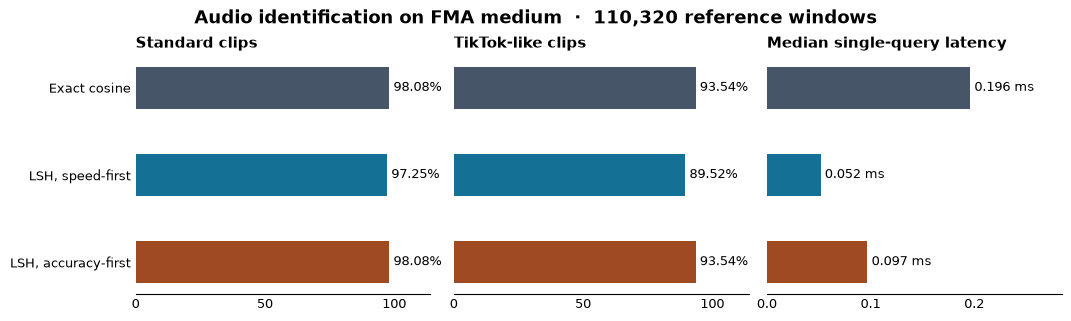

In [9]:
accuracy_choice = sweep.sort_values(
    ["dev_accuracy", "dev_lsh_median_ms"], ascending=[False, True]
).iloc[0]
accurate_bits = int(accuracy_choice.bits)
accurate_tables = int(accuracy_choice.tables)
accurate_probes = int(accuracy_choice.probes)
accurate_index = GPUAngularLSH(Rg, rtg, bits=accurate_bits, tables=accurate_tables, seed=INDEX_SEED)
accurate_tracks, accurate_scores, accurate_counts = lsh_batch(Qtestg, accurate_index, accurate_probes)
candidate = accurate_tracks.get()
assert np.all(accurate_scores.get() <= es + 2e-5)
accurate_times = paired_times(
    lambda q: gpu_exact(Rg, rtg, q),
    lambda q: accurate_index.search(q, probes=accurate_probes), Qtestg, test_order
)
accuracy_rows = []
for set_name, group in meta.groupby("query_set", sort=False):
    ids = group.index.to_numpy()
    accuracy_rows.append({"query_set": set_name, "queries": len(ids),
                          "exact_correct": int(np.sum(ep[ids] == ytest[ids])),
                          "primary_lsh_correct": int(np.sum(lp[ids] == ytest[ids])),
                          "accuracy_first_correct": int(np.sum(candidate[ids] == ytest[ids])),
                          "same_prediction_as_exact": int(np.sum(candidate[ids] == ep[ids]))})
accuracy_table = pd.DataFrame(accuracy_rows).set_index("query_set")
display(accuracy_table.filter(like="correct").div(accuracy_table.queries, axis=0).round(4))
report["accuracy_first_sensitivity"] = {
    "exploratory": True, "bits": accurate_bits, "tables": accurate_tables, "probes": accurate_probes,
    "dev_accuracy": float(accuracy_choice.dev_accuracy), "heldout": accuracy_rows,
    "single_query": {name: summary_ms(value) for name, value in accurate_times.items()},
    "mean_window_visits": float(accurate_counts.mean().item()),
}
display(pd.DataFrame(report["accuracy_first_sensitivity"]["single_query"]).T)

method_names = ["Exact cosine", "LSH, speed-first", "LSH, accuracy-first"]
method_colors = ["#475569", "#157095", "#a04a23"]
counts = accuracy_table[["exact_correct", "primary_lsh_correct", "accuracy_first_correct"]]
rates = counts.div(accuracy_table.queries, axis=0) * 100
latencies = [speed["single_query"]["exact"]["median_ms"],
             speed["single_query"]["selected_lsh"]["median_ms"],
             report["accuracy_first_sensitivity"]["single_query"]["lsh"]["median_ms"]]
fig, axes = plt.subplots(1, 3, figsize=(10.6, 3.1), sharey=True, layout="constrained")
for axis, values, heading, units in zip(axes, [rates.loc["Standard"], rates.loc["TikTok-like"], latencies],
        ["Standard clips", "TikTok-like clips", "Median single-query latency"], ["%", "%", " ms"], strict=True):
    vals = np.asarray(values)
    axis.barh(np.arange(3), vals, color=method_colors, height=.48)
    axis.set_title(heading, loc="left", fontsize=11, fontweight="bold")
    axis.set_xlim(0, 114 if units == "%" else max(vals) * 1.45)
    axis.set_xticks([0, 50, 100] if units == "%" else np.linspace(0, max(vals), 3).round(2))
    for i, value in enumerate(vals):
        label = f"{value:.2f}%" if units == "%" else f"{value:.3f} ms"
        axis.annotate(label, (value, i), xytext=(3,0), textcoords="offset points", va="center", fontsize=9)
    axis.spines[["top","right","left"]].set_visible(False)
    axis.tick_params(axis="both", length=0, labelsize=9)
axes[0].set_yticks(np.arange(3), labels=method_names)
axes[0].invert_yaxis()
fig.suptitle(f"Audio identification on FMA {TAG}  ·  {len(R):,} reference windows", fontsize=13, fontweight="bold")
for ext in ("pdf", "png"):
    output = FIG / f"gpu-operating-points-{TAG}.{ext}"
    fig.savefig(output,dpi=220,bbox_inches="tight")
    report["figures"][f"operating_points_{ext}"] = str(output.relative_to(ROOT))
JSON_PATH.write_text(json.dumps(clean(report), indent=2, allow_nan=False), encoding="utf-8")
plt.show()
